In [ ]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split


# Project paths
CURRENT_DIR = Path.cwd()
PROJECT_DIR = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

DATASET_DIR = PROJECT_DIR / "dataset"
IMAGE_DIR = DATASET_DIR / "train_images"

# Load the original APTOS dataset
df = pd.read_csv(DATASET_DIR / "train.csv")

# Basic checks
print("Total images:", len(df))
print("\nOriginal class distribution:")
print(df["diagnosis"].value_counts().sort_index())

# Check for duplicate image IDs
assert df["id_code"].is_unique, "Duplicate image IDs found!"

# Check that image files exist
missing_images = [
    image_id for image_id in df["id_code"]
    if not (IMAGE_DIR / f"{image_id}.png").exists()
]

if missing_images:
    raise FileNotFoundError(
        f"{len(missing_images)} images are missing. "
        f"Examples: {missing_images[:5]}"
    )

# First: reserve 15% for testing
train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    stratify=df["diagnosis"],
    random_state=2026
)

# Second: divide remaining data into 70% training and 15% validation
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    stratify=train_val_df["diagnosis"],
    random_state=2026
)

# Save new split files without overwriting previous files
SPLIT_DIR = DATASET_DIR / "independent_splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_df.to_csv(SPLIT_DIR / "train.csv", index=False)
val_df.to_csv(SPLIT_DIR / "validation.csv", index=False)
test_df.to_csv(SPLIT_DIR / "test.csv", index=False)

# Verify that there is no overlap
train_ids = set(train_df["id_code"])
val_ids = set(val_df["id_code"])
test_ids = set(test_df["id_code"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(train_df) + len(val_df) + len(test_df) == len(df)

# Display results
for name, split in [
    ("TRAINING", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{name} SET")
    print("Images:", len(split))
    print("Class distribution:")
    print(split["diagnosis"].value_counts().sort_index())

print("\nSUCCESS: New dataset splits created!")
print("Saved location:", SPLIT_DIR)

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.
Total images: 3662

Original class distribution:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64

TRAINING SET
Images: 2562
Class distribution:
diagnosis
0    1263
1     258
2     699
3     135
4     207
Name: count, dtype: int64

VALIDATION SET
Images: 550
Class distribution:
diagnosis
0    271
1     56
2    150
3     29
4     44
Name: count, dtype: int64

TEST SET
Images: 550
Class distribution:
diagnosis
0    271
1     56
2    150
3     29
4     44
Name: count, dtype: int64

SUCCESS: New dataset splits created!
Saved location: c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\dataset\independent_splits


In [2]:
import tensorflow as tf
import pandas as pd
import numpy as np

from pathlib import Path
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.utils.class_weight import compute_class_weight

# Project directories
PROJECT_DIR = Path.cwd().parent
DATASET_DIR = PROJECT_DIR / "dataset"
IMAGE_DIR = DATASET_DIR / "train_images"
SPLIT_DIR = DATASET_DIR / "independent_splits"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(exist_ok=True)

# Load ONLY training and validation CSV files
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

# Image dimensions and batch size
IMAGE_SIZE = 224
BATCH_SIZE = 8
NUM_CLASSES = 5

# Image preprocessing function
def load_and_preprocess_image(image_path, label):

    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=3)

    image = tf.image.resize_with_pad(
        image,
        IMAGE_SIZE,
        IMAGE_SIZE,
        antialias=True
    )

    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)

    return image, label


# Create datasets
def create_dataset(dataframe, training=False):

    image_paths = [
        str(IMAGE_DIR / f"{image_id}.png")
        for image_id in dataframe["id_code"]
    ]

    labels = dataframe["diagnosis"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df, training=False)

# Calculate class weights for imbalanced data
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2, 3, 4]),
    y=train_df["diagnosis"].values
)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("\nClass weights:", class_weights)

# Verify one batch
images, labels = next(iter(train_ds))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image value range:", float(tf.reduce_min(images)),
      "to", float(tf.reduce_max(images)))

print("\nTraining pipeline ready!")

Training images: 2562
Validation images: 550

Class weights: {0: 0.40570071258907364, 1: 1.986046511627907, 2: 0.7330472103004292, 3: 3.7955555555555556, 4: 2.47536231884058}

Image batch shape: (8, 224, 224, 3)
Label batch shape: (8,)
Image value range: -1.0 to 1.0000007152557373

Training pipeline ready!


In [3]:
import tensorflow as tf

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Load fresh MobileNetV2 with ImageNet weights
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Build our classification head
inputs = tf.keras.layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    5,
    activation="softmax",
    name="dr_predictions"
)(x)

# Complete model
model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="Independent_MobileNetV2"
)

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
model.summary()

print("\nFresh MobileNetV2 model created successfully!")

Model: "Independent_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dr_predictions (Dense)          │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Fresh MobileNetV2 model created successfully!


In [4]:
# Save the best model
head_checkpoint = MODEL_DIR / "mobilenetv2_independent_head_best.keras"

# Training callbacks
head_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(head_checkpoint),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=0.000001,
        verbose=1
    )
]

# Train the classification head
head_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=head_callbacks
)

print("\nInitial MobileNetV2 training completed!")

print(
    "Best validation accuracy:",
    round(max(head_history.history["val_accuracy"]) * 100, 2),
    "%"
)

print(
    "Best validation loss:",
    round(min(head_history.history["val_loss"]), 4)
)

Epoch 1/8


c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


320/321 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.5781 - loss: 1.3248
Epoch 1: val_loss improved from None to 0.75704, saving model to c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\models\mobilenetv2_independent_head_best.keras

Epoch 1: finished saving model to c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\models\mobilenetv2_independent_head_best.keras
321/321 ━━━━━━━━━━━━━━━━━━━━ 77s 229ms/step - accuracy: 0.5785 - loss: 1.3238 - val_accuracy: 0.6982 - val_loss: 0.7570 - learning_rate: 0.0010
Epoch 2/8
320/321 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.6727 - loss: 1.0798
Epoch 2: val_loss did not improve from 0.75704

Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
321/321 ━━━━━━━━━━━━━━━━━━━━ 59s 183ms/step - accuracy: 0.6725 - loss: 1.0795 - val_accuracy: 0.6109 - val_loss: 0.9425 - learning_rate: 0.0010
Epoch 3/8
320/321 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.7086 - loss: 0.9526
Epoch 3: val_

In [5]:
# Load the best model from initial training
model = tf.keras.models.load_model(head_checkpoint)

# Find the MobileNetV2 feature extraction model
base_model_layer = next(
    (
        layer for layer in model.layers
        if isinstance(layer, tf.keras.Model)
        and layer.name.lower().startswith("mobilenetv2")
    ),
    None
)

if base_model_layer is None:
    raise ValueError("MobileNetV2 base model could not be found!")

print("Loaded best initial checkpoint:", head_checkpoint)
print("Base model:", base_model_layer.name)
print("Total base layers:", len(base_model_layer.layers))

Loaded best initial checkpoint: c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\models\mobilenetv2_independent_head_best.keras
Base model: mobilenetv2_1.00_224
Total base layers: 154


In [6]:
# Enable fine-tuning
base_model_layer.trainable = True

# Initially freeze every layer
for layer in base_model_layer.layers:
    layer.trainable = False

# Unfreeze only the last 20 layers
for layer in base_model_layer.layers[-20:]:
    if not isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True

# Keep BatchNormalization layers frozen
print("Trainable layers:")

for layer in base_model_layer.layers[-20:]:
    if layer.trainable:
        print(layer.name)

print("\nFine-tuning configuration ready!")

Trainable layers:
block_15_expand
block_15_expand_relu
block_15_depthwise
block_15_depthwise_relu
block_15_project
block_15_add
block_16_expand
block_16_expand_relu
block_16_depthwise
block_16_depthwise_relu
block_16_project
Conv_1
out_relu

Fine-tuning configuration ready!


In [7]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning.")
print("Learning rate: 0.00001")

Model recompiled for fine-tuning.
Learning rate: 0.00001


In [8]:
finetune_checkpoint = (
    MODEL_DIR / "mobilenetv2_independent_finetuned_best.keras"
)

finetune_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(finetune_checkpoint),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=0.0000001,
        verbose=1
    )
]

finetune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weights,
    callbacks=finetune_callbacks,
    shuffle=False
)

print("\nFine-tuning completed!")

print(
    "Best validation accuracy:",
    round(max(finetune_history.history["val_accuracy"]) * 100, 2),
    "%"
)

print(
    "Best validation loss:",
    round(min(finetune_history.history["val_loss"]), 4)
)

Epoch 1/5
320/321 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.7355 - loss: 0.8822
Epoch 1: val_loss improved from None to 0.73985, saving model to c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\models\mobilenetv2_independent_finetuned_best.keras

Epoch 1: finished saving model to c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\models\mobilenetv2_independent_finetuned_best.keras
321/321 ━━━━━━━━━━━━━━━━━━━━ 70s 203ms/step - accuracy: 0.7354 - loss: 0.8824 - val_accuracy: 0.6891 - val_loss: 0.7398 - learning_rate: 1.0000e-05
Epoch 2/5
320/321 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.7758 - loss: 0.7805
Epoch 2: val_loss improved from 0.73985 to 0.66144, saving model to c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\models\mobilenetv2_independent_finetuned_best.keras

Epoch 2: finished saving model to c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\models\mobilenetv2_independent_finetuned_best.keras
321/321

In [11]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    balanced_accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns

# Load the test CSV for the first time
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

print("Independent test images:", len(test_df))

# Create test dataset without shuffling
test_ds = create_dataset(test_df, training=False)

# Load the best fine-tuned model
final_model = tf.keras.models.load_model(
    finetune_checkpoint
)

print("\nFinal model loaded successfully!")

# Evaluate the model
test_loss, test_accuracy = final_model.evaluate(
    test_ds,
    verbose=1
)

print("\nFINAL TEST RESULTS")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Independent test images: 550

Final model loaded successfully!
69/69 ━━━━━━━━━━━━━━━━━━━━ 14s 171ms/step - accuracy: 0.7764 - loss: 0.5597

FINAL TEST RESULTS
Test Loss: 0.5597
Test Accuracy: 77.64 %


69/69 ━━━━━━━━━━━━━━━━━━━━ 12s 155ms/step

CLASSIFICATION REPORT

                  precision    recall  f1-score   support

           No DR     0.9457    0.9631    0.9543       271
            Mild     0.5176    0.7857    0.6241        56
        Moderate     0.7176    0.6267    0.6690       150
          Severe     0.4643    0.4483    0.4561        29
Proliferative DR     0.5000    0.3409    0.4054        44

        accuracy                         0.7764       550
       macro avg     0.6290    0.6329    0.6218       550
    weighted avg     0.7788    0.7764    0.7727       550

Balanced Accuracy: 0.6329
Quadratic Weighted Kappa: 0.8048


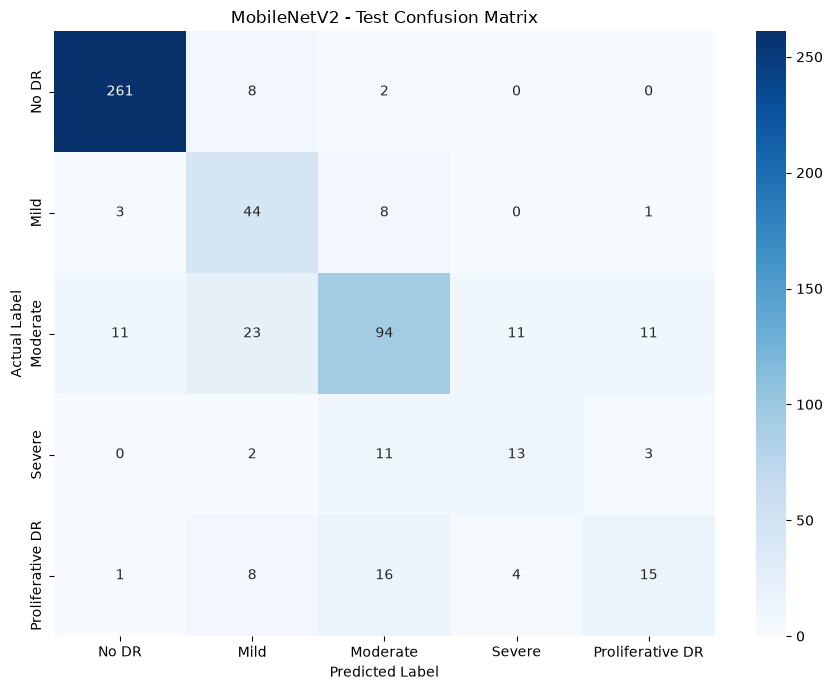

In [12]:
# Actual labels
y_true = test_df["diagnosis"].values

# Model predictions
y_prob = final_model.predict(test_ds, verbose=1)

# Convert probabilities into predicted classes
y_pred = np.argmax(y_prob, axis=1)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

# Calculate classification metrics
print("\nCLASSIFICATION REPORT\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# Additional metrics
print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_true, y_pred), 4))

print("Quadratic Weighted Kappa:",
      round(cohen_kappa_score(
          y_true, y_pred, weights="quadratic"
      ), 4))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

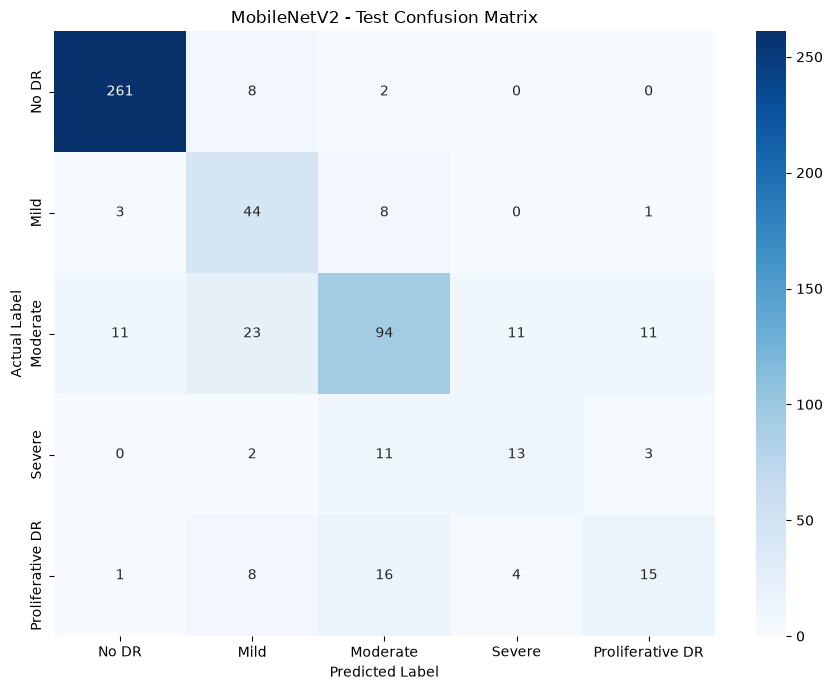


Test results saved successfully!
Output directory: c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\outputs\independent_test


In [13]:
# Create output directory
OUTPUT_DIR = PROJECT_DIR / "outputs" / "independent_test"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save individual predictions
results_df = test_df.copy()

results_df["predicted_diagnosis"] = y_pred
results_df["prediction_score"] = np.max(y_prob, axis=1)

results_df["prediction_status"] = np.where(
    results_df["diagnosis"] == results_df["predicted_diagnosis"],
    "Correct",
    "Incorrect"
)

results_df.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)

# Save confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nTest results saved successfully!")
print("Output directory:", OUTPUT_DIR)

In [14]:
import pandas as pd

SPLIT_DIR = PROJECT_DIR / "dataset" / "independent_splits"

test_df = pd.read_csv(SPLIT_DIR / "test.csv")

image_ids = [
    "233d948e2544",
    "51131b48f9d4",
    "9f436886e056",
    "24b87f744598",
    "61bbc11fe503"
]

for image_id in image_ids:
    status = (
        "TEST SET"
        if image_id in set(test_df["id_code"])
        else "NOT IN TEST SET"
    )
    print(image_id, "→", status)

233d948e2544 → NOT IN TEST SET
51131b48f9d4 → NOT IN TEST SET
9f436886e056 → NOT IN TEST SET
24b87f744598 → TEST SET
61bbc11fe503 → TEST SET


In [15]:
import pandas as pd

SPLIT_DIR = PROJECT_DIR / "dataset" / "independent_splits"

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")
test_df = pd.read_csv(SPLIT_DIR / "test.csv")

image_ids = [
    "233d948e2544",
    "51131b48f9d4",
    "9f436886e056",
    "24b87f744598",
    "61bbc11fe503"
]

splits = {
    "Training": set(train_df["id_code"]),
    "Validation": set(val_df["id_code"]),
    "Test": set(test_df["id_code"])
}

for image_id in image_ids:
    membership = [
        split_name
        for split_name, ids in splits.items()
        if image_id in ids
    ]

    print(f"{image_id} → {membership[0] if membership else 'Not found'}")

233d948e2544 → Validation
51131b48f9d4 → Training
9f436886e056 → Training
24b87f744598 → Test
61bbc11fe503 → Test
